<i>Dela Cruz, Cloie Sofia R.<i/>

<i>Morales, Rayleen Claire G.<i/>

<i>AM1<i/>

# Import Libraries

In [96]:
# This line of code will import the pandas library into the jupyter notebook.
# Pandas is a python package that we will use to analyse and manipulate our dataset.
# Using the 'as' syntax, we were able to assign the alias 'pd' to panda to reference its functions easier throughout the script.
import pandas as pd

# This line of code will import the numpy library.
# NumPy is a library in Python for the computation and manipulation of data.
# Using the 'as' syntax, we were able to assign the alias 'np' to numpy to reference its functions easier throughout the script.
import numpy as np

# Pyplot is a module within the Matplotlib library in Python.
# It provides a MATLAB-like way of generating figures and axes.
# Using the 'as' syntax, we were able to assign the alias 'plt' to matplotlib pyplot to reference its functions easier throughout the script.
import matplotlib.pyplot as plt

# This line of code will import the Seaborn library.
# Seaborn is a Phyton library used for visualization built on top of Matplotlib.
# Using 'sns,' we have given it an alias for shorthand use throughout our code.
import seaborn as sns

# This line of code imports the ConfusionMatrixDisplay class from Scikit-learn's metrics module.
# This class will be used to visually plot a confusion matrix to evaluate the classification model's performance.
from sklearn.metrics import ConfusionMatrixDisplay

# This line of code imports two tools from Scikit-learn's model_selection module.
# The train_test_split is used to randomly divide our dataset into training and training sets for model validation.
# Meanwhile, GridSearchCV can help us automatically test combinations of hyperparameters to find the best performing model through cross-validation.
from sklearn.model_selection import train_test_split, GridSearchCV

# This line of code imports the StandardScaler class from scikit-learn's preprocessing module.
# This class will help us standardize features by removing the mean and scaling to unit variance.
from sklearn.preprocessing import StandardScaler

# This line of code imports the SVC (Support Vector Classifier) from Scikit-learn's svm module.
# The SVC is the core implementation of the Support Vector Machine algorithm used for classification tasks, supporting kernels like linear, RBF, and polynomial.
from sklearn.svm import SVC

# This line of code imports multiple evaluation metrics from scikit-learn.
# The different functions will help us quantify model performance in terms of correctness (accuracy), relevance (precision), completeness (recall), detailed per-class performance (classification_report) and f1_score.
# The confusion matrix will give us a breakdown of correct vs. incorrect predictions per class.
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report, f1_score

from sklearn.decomposition import PCA

# This line of code imports the f_classif function from sklearn.feature_selection.
# The f_classif function will help us perform an ANOVA F-test between each feature and the target to assess statistical significance.
from sklearn.feature_selection import f_classif

# This line of code imports Listesd Colormap from Matplotlib's color utilities.
# This will allow us to manually define a fixed sequence of colors for plotting.
from matplotlib.colors import ListedColormap

# This line of code imports PCS (Principal Component Analysis) from Scikit-learn's decomposition module.
# We will use PCA later on as a dimensionality reduction technique to tranform our high-dimensional data into fewer components while preserving the most important variance.
from matplotlib.patches import Patch

# Load Dataset

**Load CSV File**

In [97]:
# This line of code loads the CSV file of the dataset into a pandas DataFrame named df.
# This will help us parse columns such as Age, Cholesterol, SystolicBP, BMI, ExerciseHours, Smoking, Diabetes, and HeartAttackRisk.
df = pd.read_csv('heart_attack_risk_data_ph.csv')

**Preview Data**

In [98]:
# This line of code will output the shape of our dataset.
# It will display the number of rows and columns. 
print("\nShape of dataset:", df.shape)


Shape of dataset: (1000, 8)


In [99]:
# This line of code previews the first five rows of the DataFrame df.
# This will help confirm that the data was loaded correctly and reveals the structure and values of initial records.
df.head()

,Age,Cholesterol,SystolicBP,BMI,ExerciseHours,Smoking,Diabetes,HeartAttackRisk
0,52,241.980663,109.872326,18.000000,2.273013,0,0,0
1,42,227.739010,117.832220,20.698075,3.937593,0,0,0
2,54,201.788911,108.113701,22.931972,4.036034,0,0,0
3,67,180.591897,115.380577,34.438438,4.945261,0,0,0
4,41,220.946699,91.595780,27.782766,1.266283,0,1,1


# Explore Dataset

**Summary Statistics**

In [100]:
# This line of code prints a concise summary of the DataFrame, including column names, data types, and non-null counts.
# This is important for identifying missing values and ensuring data types align with our model's needs.
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Age              1000 non-null   int64  
 1   Cholesterol      1000 non-null   float64
 2   SystolicBP       1000 non-null   float64
 3   BMI              1000 non-null   float64
 4   ExerciseHours    1000 non-null   float64
 5   Smoking          1000 non-null   int64  
 6   Diabetes         1000 non-null   int64  
 7   HeartAttackRisk  1000 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 62.6 KB
None


In [101]:
# This line of code generates a descriptive statistics (mean, std, min, max, quartiles) for each numeric column.
# This will help us detect outliers, scale differences, and understand central tendencies across features.
print(df.describe())

               Age  Cholesterol   SystolicBP          BMI  ExerciseHours  \
count  1000.000000  1000.000000  1000.000000  1000.000000    1000.000000   
mean     44.971000   202.682229   120.201911    25.112201       3.928793   
std      14.055665    28.696648    14.480513     4.757765       1.917617   
min      20.000000   150.000000    90.000000    18.000000       0.000000   
25%      35.000000   181.812749   110.280006    21.312898       2.634790   
50%      45.000000   201.892314   119.996239    25.000923       3.963516   
75%      54.000000   221.866465   129.913730    28.334727       5.278246   
max      80.000000   295.793227   178.893566    40.000000      10.000000   

           Smoking     Diabetes  HeartAttackRisk  
count  1000.000000  1000.000000      1000.000000  
mean      0.296000     0.128000         0.153000  
std       0.456719     0.334257         0.360168  
min       0.000000     0.000000         0.000000  
25%       0.000000     0.000000         0.000000  
50%      

**Target Class Distribution**

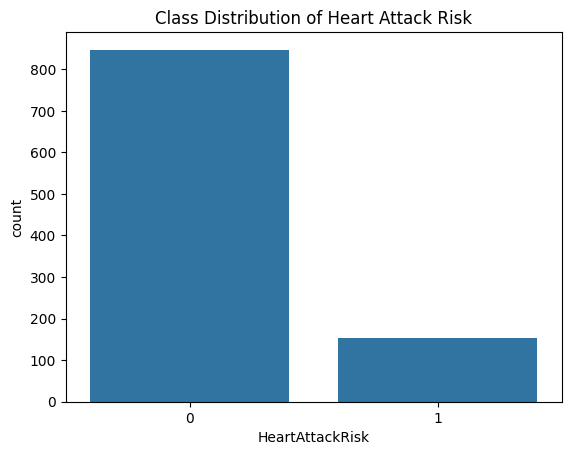

In [102]:
# This line of code uses Seaborn's countplot() to create a bar chart showing the frequency of each category in the HeartAttackRisk column.
# This will automatically cound how many data points fall into each class and allow us to check class imbalance.
sns.countplot(x='HeartAttackRisk', data=df)

# This line of code sets the title of the current Matplotlib plot to clearly describe what's being visualized.
# This helps in the readability and neatness of the code.
plt.title('Class Distribution of Heart Attack Risk')

# This command outputs the plot in our Jupyter Notebook.
# This ensures that the plot is displayed.
plt.show()

**Correlation Heatmap**

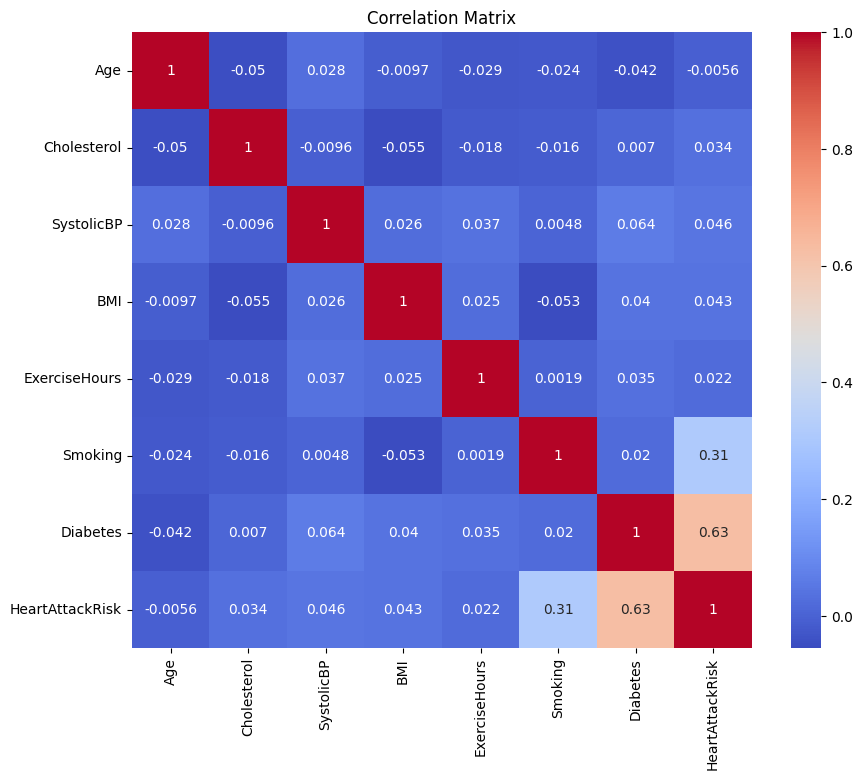

In [103]:
# This line of code initializes a new Matplotlib figure with a size of 10 by 8 units.
# This prepares the canvas for plotting before the heatmap is drawn.
plt.figure(figsize=(10,8))

# This line of code creates a heatmap for us to visualize the pairwise correlation between all numerical features.
# The 'annot=True' argument displays the exact correlation coefficients inside each cell.
# Also, the coolwarm colormap visually highlights positive and negative correlations for intuitive analysis.
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

# This line of code adds a descriptive title to the heatmap.
# This specifically labels the plot as showing a correlation matrix.
plt.title('Correlation Matrix')

# This line of code renders the figure we have constructed so far.
# This finalizes and shows the plot after configuration.
plt.show()

# Feature Importance Exploration

**Correlation with Target**

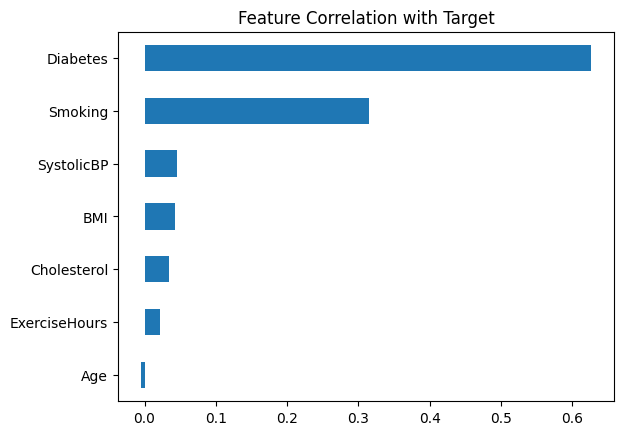

In [104]:
# This line of code computes the Pearson correlation of every feature with the target.
# The resut is a ranked list of how strongly each feature correlates with the target.
correlations = df.corr()['HeartAttackRisk'].drop('HeartAttackRisk').sort_values()

# This line of code creates a horizontal bar plot to visualize how each feature correlates with the target.
# This makes it easier to visually compare the influence of each feature because features with bars further from zero have stronger linear relationships with the target.
correlations.plot(kind='barh', title="Feature Correlation with Target")

# This command displays the generated horizontal bar chart in the jupyter notebook.
# This ensures the plot is rendered after all customization is complete. 
plt.show()

**ANOVA F-Test (Feature Scores)**

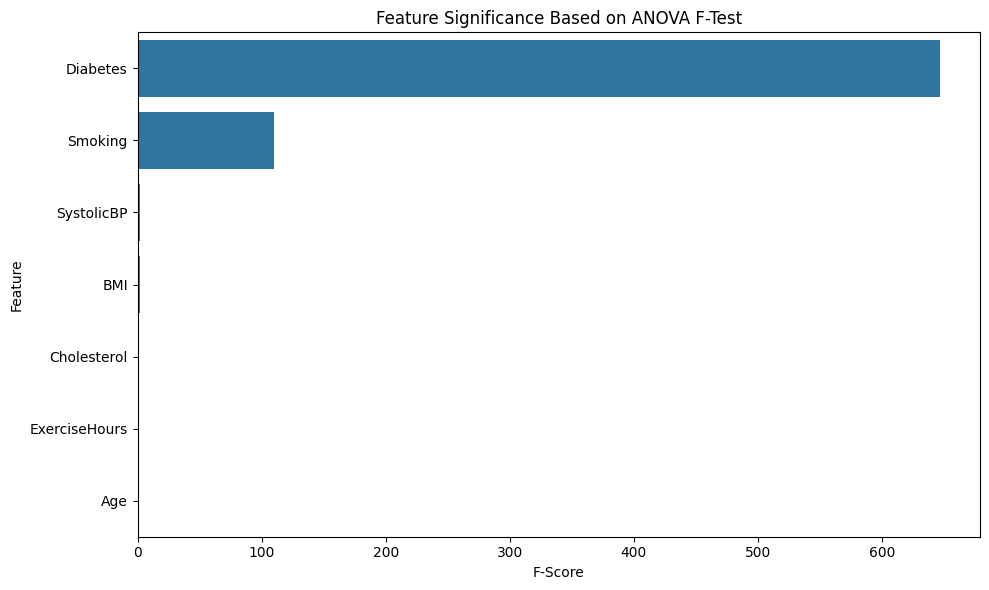

,Feature,F-Score,p-Value
6,Diabetes,646.723372,2.188197e-110
5,Smoking,109.688502,2.005685e-24
2,SystolicBP,2.092837,1.483050e-01
3,BMI,1.840687,1.751772e-01
1,Cholesterol,1.140829,2.857354e-01
4,ExerciseHours,0.476498,4.901733e-01
0,Age,0.031835,8.584258e-01


In [105]:
# This line creates a new DataFrame X containing all the input (independent) features by dropping the target column HeartAttackRisk.
# It ensures that only predictor variables are used for modeling and statistical testing, not the target itself.
X = df.drop(columns=['HeartAttackRisk'])

# This line extracts the HeartAttackRisk column from the DataFrame and assigns it to y, which represents the target or output variable.
# y must be separated from X for supervised learning workflows and statistical tests like ANOVA.
y = df['HeartAttackRisk']

# This line applies standardization to all numeric features in X and stores the result in X_scaled.
# The result is a NumPy array where each column (feature) has a mean of 0 and a standard deviation of 1, which improves the validity of the F-test.
X_scaled = StandardScaler().fit_transform(X)

# This line performs an ANOVA F-test between each feature in X_scaled and the target y, returning arrays of F-scores and corresponding p-values.
# The F-score quantifies how well each feature differentiates between the classes in the target variable (higher values = more predictive power).
# The p-values indicate statistical significance; lower values (typically < 0.05) suggest that the feature's impact is unlikely due to chance.
f_scores, p_values = f_classif(X_scaled, y)

# This line of code begins the creation of a new DataFrame anova_df to hold the results of the F-test in a tabular format.
# This is important because storing feature names, F-scores, and p-values in a DataFrame makes the results easy to explore, sort, and visualize.
anova_df = pd.DataFrame({

    # This line inserts the names of the original input features into the Feature column of the anova_df DataFrame.
    # It uses X.columns to retrieve the correct labels from the pre-scaled DataFrame so they match the F-scores and p-values.
    'Feature': X.columns,

    # This stores the computed F-test statistic for each feature under the F-Score column.
    # This metric is directly used to rank feature importance for this classification task.
    'F-Score': f_scores,

    # This column stores the statistical significance (p-values) associated with each F-score.
    # These values help determine whether the observed feature importance is statistically valid or might have occurred by random chance.
    'p-Value': p_values

# After creating the DataFrame, this line sorts it in descending order based on F-scores to prioritize the most important features.
# This makes interpretation efficient and focused for reporting or feature selection.
}).sort_values(by='F-Score', ascending=False)

# This initializes a new matplotlib figure with specified dimensions (10 by 6 units).
# It provides ample space for displaying a horizontal bar chart without overlapping labels.
plt.figure(figsize=(10, 6))

# This creates a horizontal barplot where features are plotted along the y-axis and their F-scores along the x-axis.
# This will allow us to visually compare the statistical importance of each feature based on the F-test.
sns.barplot(x='F-Score', y='Feature', data=anova_df.sort_values(by='F-Score',ascending=False))

# This line of code adds a descriptive title to the barplot, clearly stating the type of statistical test used.
# Including the method name (ANOVA F-Test) helps us understand how the importance was calculated.
plt.title('Feature Significance Based on ANOVA F-Test')

# This sets the label for the x-axis of the barplot, identifying that the horizontal scale reflects F-scores.
# Without an axis label, we might misinterpret what the bars represent.
plt.xlabel('F-Score')

# This labels the y-axis to indicate that each bar corresponds to a specific input feature.
# This is especially important for plots with multiple overlapping feature names.
plt.ylabel('Feature')

# This line of code adjusts spacing within the figure to prevent overlapping elements like labels, axes, and titles.
# Without this, some plot elements may be clipped or visually cluttered in the output.
plt.tight_layout()

# This renders and displays the barplot visualization in our notebook.
# It finalizes the figure and ensures all elements (title, axes, data bars) are visible.
plt.show()

# This line of code displays the sorted ANOVA results table directly in our notebook after the plot, reinforcing the visual with raw numeric data.
# It allows us to inspect precise F-scores and p-values feature-by-feature in descending order of significance.
anova_df.sort_values(by='F-Score', ascending=False)

# Data Preprocessing

**Feature/Target Split**

In [106]:
# This line of code creates our feature set X by dropping the target column 'HeartAttackRisk' from the DataFrame.
# It keeps all other columns that we want to use as inputs to our machine learning model.
X = df.drop(columns='HeartAttackRisk')

# This line defines our target variable y by selecting the 'HeartAttackRisk' column from the original dataset.
# y represents the output label our model will learn to predict based on the input features.
# This separation of features and target is essential for fitting any supervised machine learning algorithm.
y = df['HeartAttackRisk']

**Feature Scaling**

In [107]:
# This line initializes a StandardScaler object from scikit-learn, which standardizes features by removing the mean and scaling to unit variance.
# It prepares the scaler to learn the mean and standard deviation of each feature during the fit step.
scaler = StandardScaler()

# This line fits the StandardScaler to the feature data X and then transforms it into a scaled version.
# Each feature in X is now rescaled to have a mean of 0 and a standard deviation of 1, which ensures fair distance calculations.
# The result X_scaled is a NumPy array that contains the standardized version of our feature matrix.
X_scaled = scaler.fit_transform(X)

# Train-Test Split

In [108]:
# This line of code splits our dataset into training and testing sets using 70/30 ratio.
# The random_state=42 ensures reproducibility so we get the same split every time we run the code.
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, stratify=y, random_state=42)

# Implement Initial SVM Models

**Linear Kernel**

In [109]:
# This line of code creates an instance of Support Vector Classifier using a linear kernel 
# This separates classes with a straight line or hyperplane in higher dimensions.
svm_linear = SVC(kernel='linear')

# This line of code trains the linear SVM model using our training features and labels.
# The algorithm learns a decision boundary that best separates the classes with maximum margin.
svm_linear.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


**RBF (Radial Basis Function) Kernel**

In [110]:
# This line of code initializes a SVC using the RBF kernel, allowing nonlinear decision boundaries.
# The RBF kernels are effective when our data isn't linearly separable.
svm_rbf = SVC(kernel='rbf')

# This line of code trains the RBF-based SVM model on the provided training set.
# The model will determine the best curved boundary that separates high-risk and low-risk individuals.
svm_rbf.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


**Polynomial Kernel**

In [111]:
# This creates a Support Vector Classifier using a polynomial kernal of degree 3.
# This means it will try to fit a cubic deicison boundary to the data.
svm_poly = SVC(kernel='poly', degree=3)

# This trains the polynomial SVM model using our training features and target labels.
# This optimizes the cubic boundary to separate the heart attack risk classes with maximum margin.
svm_poly.fit(X_train, y_train)

,C,1.0
,kernel,'poly'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


# Evaluate Initial SVM Models

**Accuracy, Precision, and Recall**


Linear Kernel
Accuracy: 0.9066666666666666
Precision: 0.725
Recall: 0.6304347826086957

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.95       254
           1       0.72      0.63      0.67        46

    accuracy                           0.91       300
   macro avg       0.83      0.79      0.81       300
weighted avg       0.90      0.91      0.90       300



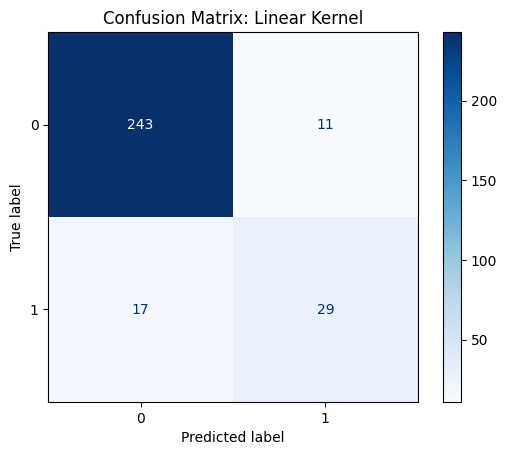


RBF Kernel
Accuracy: 0.9066666666666666
Precision: 0.725
Recall: 0.6304347826086957

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.95       254
           1       0.72      0.63      0.67        46

    accuracy                           0.91       300
   macro avg       0.83      0.79      0.81       300
weighted avg       0.90      0.91      0.90       300



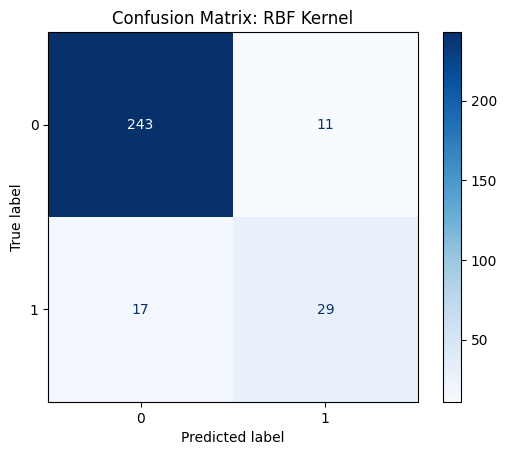


Polynomial Kernel
Accuracy: 0.9033333333333333
Precision: 0.717948717948718
Recall: 0.6086956521739131

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.94       254
           1       0.72      0.61      0.66        46

    accuracy                           0.90       300
   macro avg       0.82      0.78      0.80       300
weighted avg       0.90      0.90      0.90       300



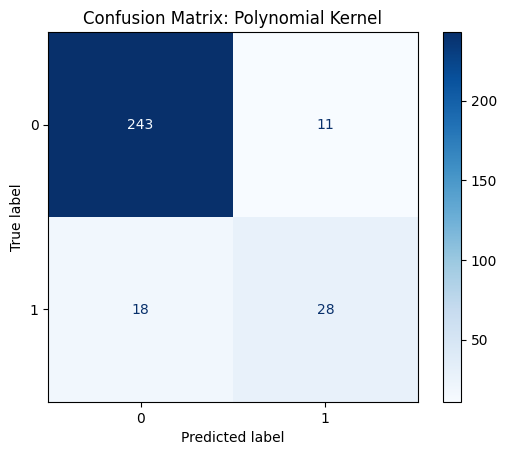

In [112]:
# In this part, we define a reusable function neames evaluate_model that takes four parameters: the model’s name, the trained model itself, the test features (X_test), and the corresponding labels (y_test).
# We can evaluate a model's performance consistently using this function.
def evaluate_model(name, model, X_test, y_test):

    # This line uses the trained model to generate predictions on the test dataset.
    # These predictions will later be compared to the true values.
    y_pred = model.predict(X_test)

    # This line prints the model's name for visual separation.
    # The ANSI escape code \033[1m starts bold text and \033[0 ends it.
    print(f"\n\033[1m{name}\033[0m")

    # This line prints the accuracy metric.
    # It shows the overall correctness of predictions.
    print("Accuracy:", accuracy_score(y_test, y_pred))

    # This line prints the precision classification metric.
    # It tells us how many predicted positives were correct.
    print("Precision:", precision_score(y_test, y_pred))

    # This line prints the recall metric.
    # It tells us ow many actual positives were correctly predicted.
    print("Recall:", recall_score(y_test, y_pred))

    # This line prints a detailed classification report for each class.
    # This is useful for deeper performance breakdown.
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    # This generates a visual confusion matrix.
    # This shows true positives, false positives, false negatives, and true negatives.
    disp = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))

    # The matrix is color-coded.
    # It uses the "Blues" colormap for clarity.
    disp.plot(cmap="Blues")

    # This line adds a title with the model name.
    # This ensures that we know ehich result the matrix is referring to.
    plt.title(f"Confusion Matrix: {name}")

    # This renders the confusion matrix plot.
    # It finalizes the visualization process.
    plt.show()

# This line calls the evaluate_model() function for the SVM linear model.
# This runs the full evaluation process for this model.
evaluate_model("Linear Kernel", svm_linear, X_test, y_test)

# This line calls the evaluate_model() function for the SVM RBF model.
# This runs the full evaluation process for this model.
evaluate_model("RBF Kernel", svm_rbf, X_test, y_test)

# This line calls the evaluate_model() function for the SVM polynomial model.
# This runs the full evaluation process for this model.
evaluate_model("Polynomial Kernel", svm_poly, X_test, y_test)

# Hyperparameter Tuning 

**Parameter Grid Setup**

In [113]:
# This dictionary defines the hyperparameters for the linear SVM Model.
# This will help in conducting the GridSearchCV later.
param_grid_linear = {

    # C controls the regularization strength.
    # This means that lower values increase margin tolerance (so less overfitting), while higher values force the model to classify every training example correctly (risks overfitting) (scikit-learn developers, 2025b).
    'C': [0.01, 0.1, 1, 10, 100],

    # We only specify kernel:['linear'] here to ensure GridSearchCV restricts itself to linear models.
    # This avoid evaluating irrelevant hyperparameters like gamma or degree.
    'kernel': ['linear']
}

# This dictionary sets the hyperparameter grid for RBF SVM.
# This model can accomodate nonlinear boundaries.
param_grid_rbf = {

    # Again, C controls the regularization strength.
    # We can control it to lessen overfitting.
    'C': [0.01, 0.1, 1, 10, 100],

    # The gamma controls how far the influence of a single training example reaches.
    # Small gamma means far reach (smoother), while large gamma makes it more localized (so complex) (scikit-learn developers, 2025a).
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],

    # We only specify rbf here to ensure GridSearchCV restricts itself to RBF kernel. 
    # This grid explores combinations of C and gamma values while being restricted to the RBF kernel.
    'kernel': ['rbf']
}

# This defines the hyperparameters range for polynomial SVMs.
# This allows curved boundaries of varying complexity.
param_grid_poly = {

    # C controls the regularization strength.
    # This allows us to possibly lessen overfitting.
    'C': [0.01, 0.1, 1, 10, 100],

    # The gamma controls how far the influence of a single training example reaches.
    # Small gamma means far reach (smoother), while large gamma makes it more localized (so complex).
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],

    # degree controls the polynomial order.
    # This allows the model to try quadratic, cubic, or quartic curves.
    'degree': [2, 3, 4],

    # This grid confines the search to the poly kernel.
    # This ensure maximum relevance. 
    'kernel': ['poly']
}

**GridSearchCV Execution**

In [114]:
# This line of code initializes an empty dictionary to store the best SVM model for each kernel type.
# Each key will correspond to a kernal and makes it easier to organize and retrieve the optimized models later.
best_models = {}

In [115]:
# This sets up a grid search using 5-fold cross-validation to find the best linear SVM based on the param_grid_linear values.
# verbose=1 gives progress output during training.
# Grid search is a model hyperparameter optimization technique. It is used to find the best combination of parameters to improve model accuracy (Nashaat, 2023).
grid_linear = GridSearchCV(SVC(), param_grid_linear, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# This runs the full grid search process on the training set for the linear kernel.
# Each combination of C in the param grid is evaluated using cross-validation.
grid_linear.fit(X_train, y_train)

# This prints out the best hyperparameters found by GridSearchCV for the linear SVM.
# It helps us document and interpret which value of C led to the best performance.
print("\nBest Linear SVM Params:", grid_linear.best_params_)

# This saves the best trained linear model into the best_models dictionary under the key 'Linear'.
# best_estimator_ returns the full model trained with the best hyperparameters on the entire training set (scikit-learn, 2025).
best_models['Linear'] = grid_linear.best_estimator_

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best Linear SVM Params: {'C': 0.01, 'kernel': 'linear'}


In [116]:
# This line of code creates a new GridSearchCV instance to search over the RBF kernel’s parameter space.
# It will iterate through combinations of C and gamma while keeping kernel='rbf'.
grid_rbf = GridSearchCV(SVC(), param_grid_rbf, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# This performs the hyperparameter search and training for all combinations in param_grid_rbf.
# After running, it stores the best scoring model internally as best_estimator_.
grid_rbf.fit(X_train, y_train)

# This displays the best hyperparameters found for the RBF model based on cross-validation accuracy.
# We'll see which pair of C and gamma performed the best.
print("\nBest RBF SVM Params:", grid_rbf.best_params_)

# Stores the best-performing RBF model into the best_models dictionary under 'RBF'.
# This ensures consistent structure across all three model types.
best_models['RBF'] = grid_rbf.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best RBF SVM Params: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}


In [117]:
# Sets up a third GridSearchCV run specifically for polynomial SVMs.
# It will iterate over combinations of C, gamma, and degree.
grid_poly = GridSearchCV(SVC(), param_grid_poly, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# Executes the hyperparameter search and training for the polynomial kernel.
# Each model is trained and validated 5 times per configuration.
grid_poly.fit(X_train, y_train)

# Prints the best C, gamma, and degree values found for the polynomial kernel.
# This gives insight into what level of model complexity worked best.
print("\nBest Polynomial SVM Params:", grid_poly.best_params_)

# Saves the trained best polynomial SVM model into the dictionary under 'Polynomial'.
# This finalizes the process of optimizing all three kernels.
best_models['Polynomial'] = grid_poly.best_estimator_

Fitting 5 folds for each of 90 candidates, totalling 450 fits

Best Polynomial SVM Params: {'C': 1, 'degree': 3, 'gamma': 'scale', 'kernel': 'poly'}


# Implement Optimized SVM Models

**Retrieve and Assign Each Optimized Model**

In [118]:
# This retrieves the best-performing linear SVM model stored under the 'Linear' key in the best_models dictionary.
# It was previously selected by GridSearchCV above.
svm_linear_optimized = best_models['Linear']

# This retrieves the best-performing RBF SVM model from the same dictionary.
# It was tuned specifically for the 'rbf' kernel, considering both C and gamma.
svm_rbf_optimized = best_models['RBF']

# This accesses the best polynomial SVM that was optimized over C, gamma, and degree.
# It’s now stored in svm_poly_optimized for clarity and usability.
svm_poly_optimized = best_models['Polynomial']

# Evaluate Optimized Models

**Performance Metrics**


Optimized Linear SVM
Accuracy: 0.9066666666666666
Precision: 0.725
Recall: 0.6304347826086957

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.95       254
           1       0.72      0.63      0.67        46

    accuracy                           0.91       300
   macro avg       0.83      0.79      0.81       300
weighted avg       0.90      0.91      0.90       300



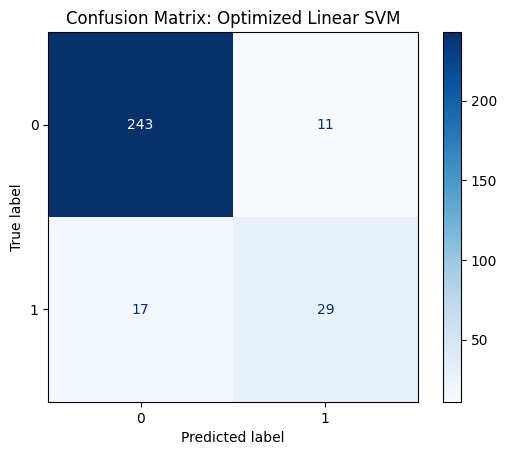

In [119]:
# This line of code calls our evaluate_model function to test the performance of the optimized linear SVM on the test set.
# It prints classification metrics like accuracy, precision, recall, F1-score, and plots a confusion matrix for visual interpretation.
evaluate_model("Optimized Linear SVM", svm_linear_optimized, X_test, y_test)


Optimized RBF SVM
Accuracy: 0.9066666666666666
Precision: 0.725
Recall: 0.6304347826086957

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.95       254
           1       0.72      0.63      0.67        46

    accuracy                           0.91       300
   macro avg       0.83      0.79      0.81       300
weighted avg       0.90      0.91      0.90       300



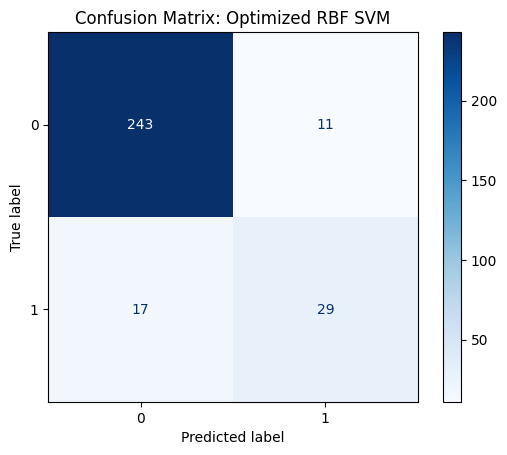

In [120]:
# This line evaluates the optimized RBF SVM, applying the same standardized performance checks.
# The test results reflect how well the radial model generalizes after being tuned on parameters like C and gamma.
evaluate_model("Optimized RBF SVM", svm_rbf_optimized, X_test, y_test)


Optimized Polynomial SVM
Accuracy: 0.9033333333333333
Precision: 0.717948717948718
Recall: 0.6086956521739131

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.94       254
           1       0.72      0.61      0.66        46

    accuracy                           0.90       300
   macro avg       0.82      0.78      0.80       300
weighted avg       0.90      0.90      0.90       300



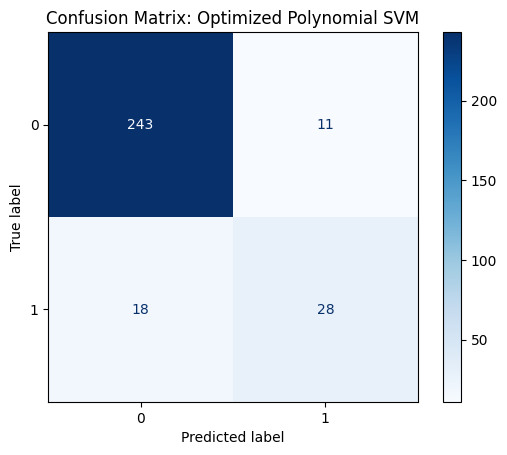

In [121]:
# Here, we evaluate the optimized polynomial SVM, which is more complex due to its use of degree and gamma.
# Labeling it as "Optimized Polynomial SVM" ensures clarity in reports, plots, and comparison tables.
evaluate_model("Optimized Polynomial SVM", svm_poly_optimized, X_test, y_test)

# Visualize Models' Decision Boundary

**Dimensionality Reduction (PCA)**

In [122]:
# This function will be used to visualize the decision boundary of our SVM models.
# It will help us understand how well the model separates classes in 2D space after PCA.
def visualize_svm_decision_boundary(model: SVC, model_name: str, X_train, X_test, y_train, y_test):

    # This line initializes a PCA object to reduce features to 2D.
    # Reducing to 2D is necessary for plotting on a 2D graph while preserving variance (GeeksForGeeks, 2025).
    pca = PCA(n_components=2)

    # This line fits PCA to the training set and transforms it into a 2D representation.
    # The result is a compressed version of X_train containing only two principal components.
    X_train_2D = pca.fit_transform(X_train)

    # This line code transforms the test data using the already-fitted PCA model from training.
    # This ensures the test set is projected into the same 2D space as the training set.
    X_test_2D = pca.transform(X_test)

    # This line of code creates a new SVM classifier.
    # It uses the same hyperparameters as the original model.
    model_2D = SVC(

        # This line ensures that the kernel matches the stored kernel.
        # Its values will be linear, rbf, and polynomial.
        kernel=model.kernel,

        # This line ensures that the SVM model will use consistent C values.
        # These C values will be sourced from the given model.
        C=model.C,

        # This line of code uses conditional logic.
        # The gamma and degree will only be included when required by the kernel type.
        gamma=model.gamma if model.kernel in ['rbf', 'poly'] else 'scale',

        # This line of code also uses conditional logic.
        # The degree will be equal to 3 if the kernel type is not polynomial.
        degree=model.degree if model.kernel == 'poly' else 3,

        # This line of code assigns a balanced class weight.
        # This is appropriate for imbalanced data.
        class_weight='balanced'
    )

    # This line treats the new 2D SVM model using PCA-reduced training data.
    # This is necessary because the decision boundary depends on the input space.
    model_2D.fit(X_train_2D, y_train)

    # This line defines the horizontal range for the plot based on the first PCA component of test data.
    # It subtracts and adds 1 to the minimum and maximum to provide padding for visualization.
    x_min, x_max = X_test_2D[:, 0].min() - 1, X_test_2D[:, 0].max() + 1

    # This line defines the vertical range for the plot based on the second PCA component of test data.
    # The ranges are used to build the meshgrid later.
    y_min, y_max = X_test_2D[:, 1].min() - 1, X_test_2D[:, 1].max() + 1
    
    # This line creates a dense grid of coordinates covering the entire plot space with 500 points along each axis.
    # Each point in this grid will be used to predict class labels and color regions.
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    # This line predicts class labels for every point in the meshgrid using the trained 2D model.
    # It reshapes the predictions into a matrix matching the grid's shape.
    Z = model_2D.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # This line defines a background color map for the decision regions.
    # The two colors represent the two predicted classes (low risk and high risk).
    cmap_background = ListedColormap(['#FFDDC1', '#C1D3FF'])
    
    # This line defines the color map for the actual data points.
    # The two colors contrast sharply with the background for clear separation.
    cmap_points = ListedColormap(['#D43F00', '#003F88'])
    
    # This line creates a new figure for the plot with a specified size.
    # A larger figure helps in rendering a detailed and readable chart.
    plt.figure(figsize=(8, 6))

    # This line draws the filled contour plot of decision regions using the prediction matrix Z.
    # The alpha value makes the background semi-transparent so that points are still visible.
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_background)

    # This line overlays the test data points onto the contour plot.
    # It uses actual labels to color the points and adds a border for better visibility.
    scatter = plt.scatter(X_test_2D[:, 0], X_test_2D[:, 1], c=y_test, cmap=cmap_points, s=40, edgecolor='k', linewidth=0.5)

    # This line retrieves the handles (color patches) from the scatter plot.
    # These handles correspond to each class present in the test labels.
    handles, _ = scatter.legend_elements()

    # This line adds a legend to the plot explaining what each color of dot means.
    # It ensures clarity for anyone viewing the visualization.    
    plt.legend(handles, ["Low Risk", "High Risk"], loc='upper right', title="True Labels")

    # This line sets the plot title using the model name provided to the function.
    # It highlights that the boundary shown is for PCA-reduced data.
    plt.title(f"SVM Decision Boundary - {model_name} (PCA Reduced)", fontsize=14, weight='bold')

    # This line labels the x-axis as the first principal component.
    # It helps us understand what the horizontal axis represents.
    plt.xlabel("Principal Component 1")

    # This line labels the y-axis as the second principal component.
    # It follows the same logic as labeling the x-axis.
    plt.ylabel("Principal Component 2")

    # This line adds a light dashed grid to the plot.
    # It helps in visually estimating the position of points and boundaries.
    plt.grid(True, linestyle='--', alpha=0.3)

    # This line adjusts plot elements to fit within the figure boundaries.
    # It prevents label and title clipping.
    plt.tight_layout()

    # This line renders the final plot.
    # It's the last step to display the decision boundary visualization.
    plt.show()

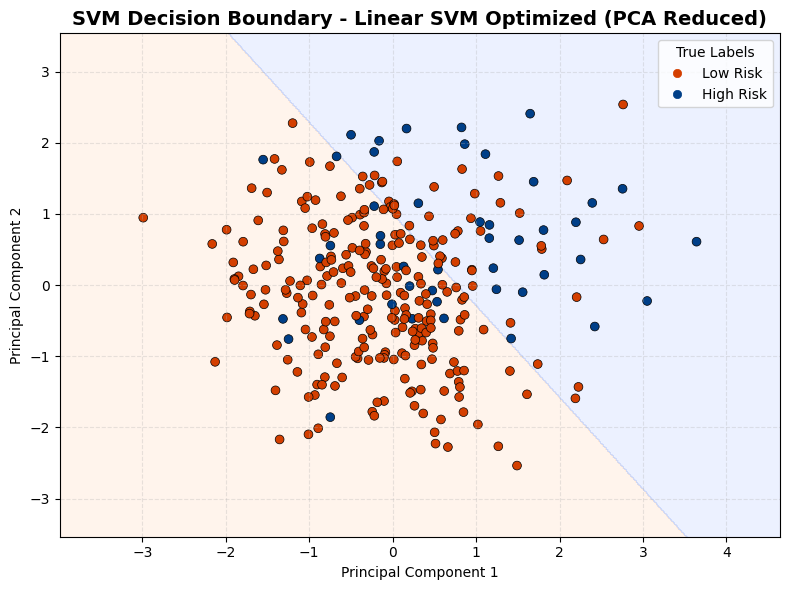

In [123]:
# This line calls the helper function to visualize the decision boundary of the optimized Linear SVM model.
# It passes the model along with the training and testing datasets to the function.
visualize_svm_decision_boundary(svm_linear_optimized, "Linear SVM Optimized", X_train, X_test, y_train, y_test)

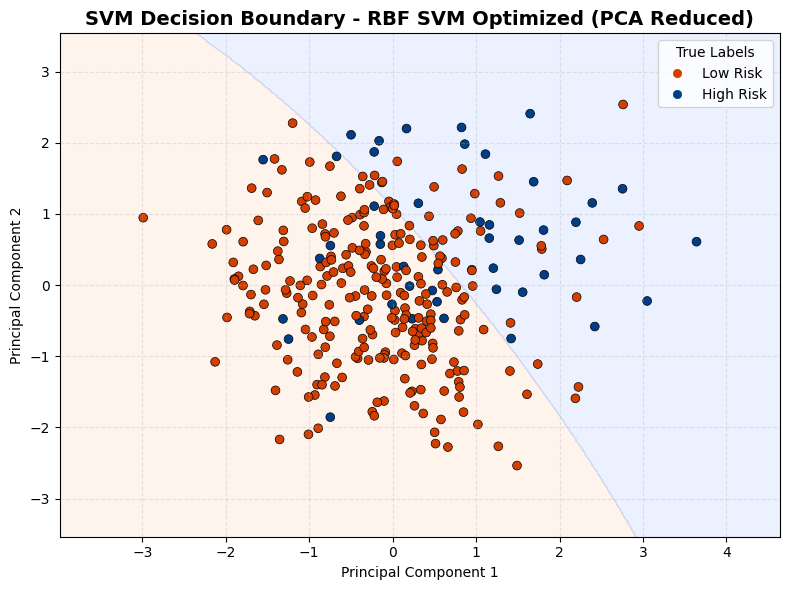

In [124]:
# This line of code sends the RBF-optimized SVM model to the visualization function to see how it classifies in 2D PCA space.
# The function will retrain the model on PCA-reduced data and plot its decision boundaries.
visualize_svm_decision_boundary(svm_rbf_optimized, "RBF SVM Optimized", X_train, X_test, y_train, y_test)

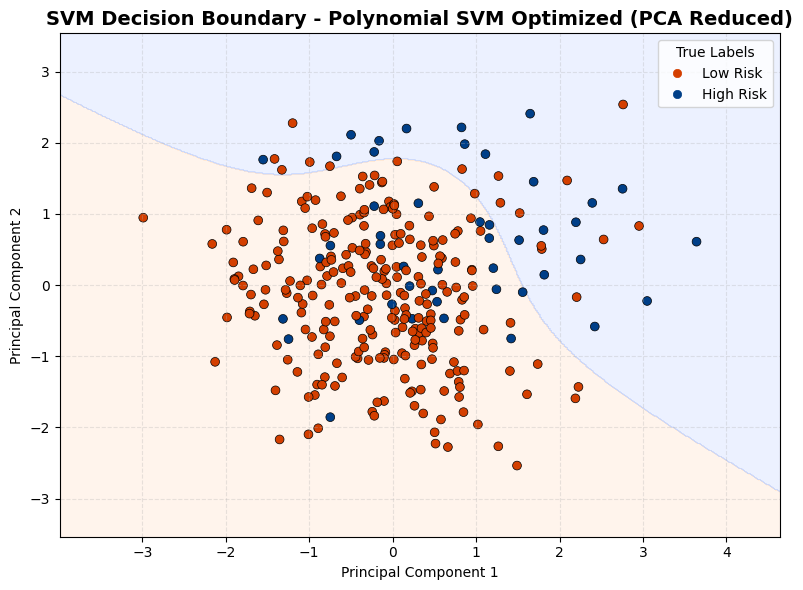

In [125]:
# This line of code executes the same visualization process but with the Polynomial SVM model.
# It shows how the polynomial kernel’s curved boundaries behave when reduced to 2D for interpretation.
visualize_svm_decision_boundary(svm_poly_optimized, "Polynomial SVM Optimized", X_train, X_test, y_train, y_test)

# Discuss Findings

Discussion is found in separate PDF file. 

# References

- GeeksForGeeks. (2025, July 11). Principal Component Analysis(PCA). GeeksforGeeks.
- Nashaat, M. (2023, October 22). Hyperparameter Tuning with GridSearchCV | by Mohammed Nashaat. Medium. 
- scikit-learn developers. (2025). GridSearchCV — scikit-learn 1.7.1 documentation. Scikit-learn.
- scikit-learn developers. (2025a). RBF SVM parameters — scikit-learn 1.7.1 documentation. Scikit-learn.
- scikit-learn developers. (2025b). SVC — scikit-learn 1.7.1 documentation. Scikit-learn. 